<a href="https://colab.research.google.com/github/seif-356/DSAI-413-multimedia-project/blob/claude%2Fnice-pascal-xief2d/festive-hypatia-wn53pf/project1_alzheimer/Project1_Multimodal_Alzheimer.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Project 1 — Multimodal Alzheimer's Disease Classification (MRI + Clinical Text)
**DSAI 413 — Multimedia**

| Branch | Method | Features |
|---|---|---|
| MRI | CNN (ResNet-50) + ViT (ViT-B/16), ImageNet-pretrained, frozen; mean over 8 axial slices | `FI` (2048 + 768) |
| Text | Clinical/cognitive record written as text → TF-IDF **and** BERT (`bert-base-uncased`, mean-pooled) | `FT` |
| Fusion | Feature-level concatenation `F_fusion = [FI, FT]` | |
| Classifier | Fully connected layers + Softmax → **CN / MCI / AD** | |

**Dataset:** OASIS-1 (cross-sectional), same patients in both modalities.
- MRI: `ninadaithal/imagesoasis` (OASIS-1 T1 scans exported as axial JPG slices, file names carry the subject ID).
- Clinical records: `jboysen/mri-and-alzheimers` → `oasis_cross-sectional.csv` (sex, handedness, age, education, SES, MMSE, CDR, eTIV, nWBV, ASF).

**Why not ADNI:** ADNI requires an access application whose approval takes longer than the deadline. OASIS is the open alternative with the same two modalities.

**Labels (from CDR):** CDR 0 → CN, CDR 0.5 → MCI (very mild impairment), CDR ≥ 1 → AD. **CDR is never put in the text** (it *is* the label).

**Evaluation protocol:** patient-level stratified 5-fold cross-validation (one scan per patient, so no patient appears in both train and test). Every model is evaluated on **exactly the same patient-level test folds**, × 3 seeds.
Metrics: accuracy, balanced accuracy, macro precision/recall/F1, Cohen's κ, macro ROC-AUC, confusion matrices, McNemar's test (fusion vs best single modality).

> Runs on **Google Colab** (T4 GPU; outputs on Drive) **or a Mac** (Apple GPU; outputs in `~/DSAI413/MM_Project1`). Run all cells.

In [2]:
# 1) Setup — works on Google Colab (CUDA) and on a Mac (Apple-silicon GPU via MPS)
%pip -q install kagglehub seaborn transformers

import os, sys, re, glob, json, random, shutil, warnings
import numpy as np, pandas as pd
import torch, torch.nn as nn
import matplotlib.pyplot as plt, seaborn as sns
from PIL import Image
from tqdm.auto import tqdm
from IPython.display import display
warnings.filterwarnings('ignore')

IN_COLAB = 'google.colab' in sys.modules
DEVICE = 'cuda' if torch.cuda.is_available() else 'mps' if torch.backends.mps.is_available() else 'cpu'
print('Device:', DEVICE, '| Colab:', IN_COLAB)

if IN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
    ROOT = '/content/drive/MyDrive/MM_Project1'
else:
    ROOT = os.path.expanduser('~/DSAI413/MM_Project1')
FEAT, RES, DSET = f'{ROOT}/features', f'{ROOT}/results', f'{ROOT}/dataset'
for d in (FEAT, RES, DSET): os.makedirs(d, exist_ok=True)

Device: cuda | Colab: True
Mounted at /content/drive


In [3]:
# 2) Config
SEEDS    = [0, 1, 2]
N_FOLDS  = 5
N_SLICES = 8          # axial slices per patient (evenly spaced over the available central slices)
PCA_DIM  = 64         # each modality block is reduced to the same size (fitted on the training fold only)
LABELS   = ['CN', 'MCI', 'AD']

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
set_seed(0)

## 3) Download both modalities (public Kaggle mirrors of OASIS-1)

In [4]:
import kagglehub
# Public datasets download without login. If it asks for credentials: Colab → Secrets → add KAGGLE_USERNAME and KAGGLE_KEY.
IMG_ROOT = kagglehub.dataset_download('ninadaithal/imagesoasis')
CSV_ROOT = kagglehub.dataset_download('jboysen/mri-and-alzheimers')
CSV_PATH = glob.glob(f'{CSV_ROOT}/**/oasis_cross-sectional.csv', recursive=True)[0]
all_jpg = glob.glob(f'{IMG_ROOT}/**/*.jpg', recursive=True)
print('MRI slices found:', len(all_jpg), '| CSV:', CSV_PATH)
print('Example file names:', [os.path.basename(p) for p in all_jpg[:3]])

Using Colab cache for faster access to the 'imagesoasis' dataset.
Using Colab cache for faster access to the 'mri-and-alzheimers' dataset.
MRI slices found: 86437 | CSV: /kaggle/input/mri-and-alzheimers/oasis_cross-sectional.csv
Example file names: ['OAS1_0302_MR1_mpr-3_154.jpg', 'OAS1_0114_MR1_mpr-1_130.jpg', 'OAS1_0150_MR1_mpr-3_129.jpg']


## 4) Align the two modalities on the same patients

In [5]:
# --- clinical records ---
clin = pd.read_csv(CSV_PATH)
clin = clin[clin.ID.str.endswith('_MR1') & clin.CDR.notna()].copy()      # first visit only; only subjects with a clinical rating
clin['subject'] = clin.ID.str[:9]                                          # OAS1_xxxx
clin['label_name'] = np.select([clin.CDR == 0, clin.CDR == 0.5], ['CN', 'MCI'], 'AD')
clin['label'] = clin.label_name.map({n: i for i, n in enumerate(LABELS)})

# --- MRI slices: OAS1_0001_MR1_mpr-1_100.jpg -> subject, scan number, slice index ---
pat = re.compile(r'(OAS1_\d{4})_MR1_mpr-(\d+)_(\d+)\.jpg$')
rows = []
for p in all_jpg:
    m = pat.search(os.path.basename(p))
    if m: rows.append(dict(subject=m.group(1), mpr=int(m.group(2)), slice=int(m.group(3)), path=p))
sl = pd.DataFrame(rows)
assert len(sl), 'File-name pattern not found - check the example names printed above and adjust `pat`.'
sl = sl.drop_duplicates(['subject', 'mpr', 'slice'])      # the same slice can appear in two folders of the mirror
first_mpr = sl.groupby('subject').mpr.min()               # one acquisition per patient
sl = sl[sl.mpr == sl.subject.map(first_mpr)]

def pick_slices(g):
    g = g.sort_values('slice')
    idx = np.linspace(0, len(g) - 1, N_SLICES).round().astype(int)
    return list(g.path.values[idx])
slices = sl.groupby('subject').apply(pick_slices).rename('slices')

df = clin.merge(slices, left_on='subject', right_index=True).reset_index(drop=True)
print('Patients with BOTH an MRI and a clinical record:', len(df))
display(df.label_name.value_counts().reindex(LABELS).to_frame('patients'))
assert df.subject.is_unique, 'one row per patient expected'

Patients with BOTH an MRI and a clinical record: 200


,patients
label_name,
CN,119
MCI,58
AD,23


## 5) Describe the two data modalities
**Modality 1 — MRI (image).** T1-weighted structural brain MRI (OASIS-1, 1.5 T, atlas-registered, skull-stripped). Each patient's 3-D volume is represented by 8 axial slices; atrophy (enlarged ventricles, widened sulci, hippocampal shrinkage) is the visual cue.

**Modality 2 — Clinical text.** Each patient's clinical and cognitive-assessment record (demographics, education, socioeconomic status, MMSE cognitive score, brain-volume measurements) is written as a short clinical note. The CDR rating is **excluded** because it defines the label.

,patients,age_mean,age_sd,mmse_mean,mmse_sd,nwbv_mean,female_pct
label_name,,,,,,,
CN,119,69.04,14.25,29.14,1.12,0.77,71.43
MCI,58,75.97,6.99,25.41,3.67,0.73,55.17
AD,23,78.70,7.70,20.91,4.12,0.70,78.26


[CN] female patient, 74 years old, right-handed, age group seventies. education level 2 of 5, socioeconomic status 3 of 5. mini mental state examination score 29 of 30, cognition mmse_normal. estimated total intracranial volume 1344 cm3, normalized whole brain volume 0.743, brain volume nwbv_mid.
[MCI] female patient, 73 years old, right-handed, age group seventies. education level 4 of 5, socioeconomic status 3 of 5. mini mental state examination score 27 of 30, cognition mmse_normal. estimated total intracranial volume 1454 cm3, normalized whole brain volume 0.708, brain volume nwbv_mid.
[AD] female patient, 86 years old, right-handed, age group eighties_plus. education level 2 of 5, socioeconomic status 4 of 5. mini mental state examination score 27 of 30, cognition mmse_normal. estimated total intracranial volume 1449 cm3, normalized whole brain volume 0.738, brain volume nwbv_mid.


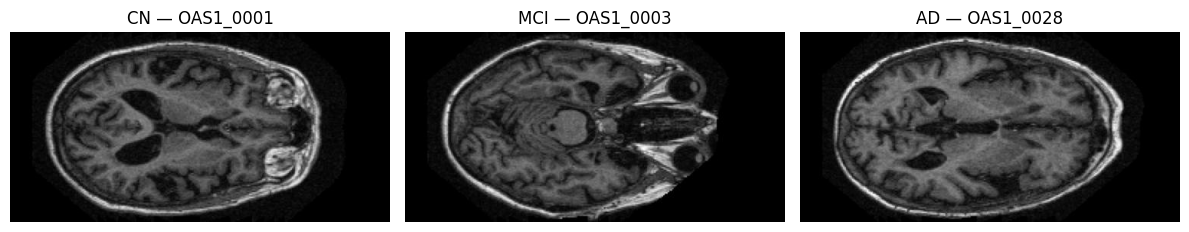

In [6]:
def fmt(v, f='{:.0f}'):
    return 'unknown' if pd.isna(v) else f.format(v)

def band(v, cuts, names):
    if pd.isna(v): return 'unknown'
    for c, n in zip(cuts, names):
        if v < c: return n
    return names[-1]

def clinical_note(r, include_mmse=True):
    sex = 'female' if r['M/F'] == 'F' else 'male'
    hand = 'right-handed' if r['Hand'] == 'R' else 'left-handed'
    t = (f"{sex} patient, {fmt(r.Age)} years old, {hand}, age group {band(r.Age, [60, 70, 80], ['under60','sixties','seventies','eighties_plus'])}. "
         f"education level {fmt(r.Educ)} of 5, socioeconomic status {fmt(r.SES)} of 5. ")
    if include_mmse:
        t += (f"mini mental state examination score {fmt(r.MMSE)} of 30, cognition "
              f"{band(r.MMSE, [21, 27], ['mmse_impaired','mmse_borderline','mmse_normal'])}. ")
    t += (f"estimated total intracranial volume {fmt(r.eTIV)} cm3, normalized whole brain volume {fmt(r.nWBV, '{:.3f}')}, "
          f"brain volume {band(r.nWBV, [0.70, 0.75], ['nwbv_low','nwbv_mid','nwbv_high'])}.")
    return t

df['text']         = df.apply(clinical_note, axis=1)
df['text_no_mmse'] = df.apply(lambda r: clinical_note(r, include_mmse=False), axis=1)

# Modality summary table
desc = df.groupby('label_name').agg(patients=('subject','size'), age_mean=('Age','mean'), age_sd=('Age','std'),
                                    mmse_mean=('MMSE','mean'), mmse_sd=('MMSE','std'), nwbv_mean=('nWBV','mean'),
                                    female_pct=('M/F', lambda s: 100*(s=='F').mean())).reindex(LABELS).round(2)
desc.to_csv(f'{RES}/modality_summary.csv'); display(desc)
for n in LABELS:
    print(f'[{n}]', df[df.label_name == n].text.iloc[0])

# One example MRI per class
fig, axes = plt.subplots(1, 3, figsize=(12, 4.3))
for ax, n in zip(axes, LABELS):
    r = df[df.label_name == n].iloc[0]
    ax.imshow(Image.open(r.slices[N_SLICES // 2]).convert('L'), cmap='gray'); ax.set_title(f'{n} — {r.subject}'); ax.axis('off')
plt.tight_layout(); plt.savefig(f'{RES}/mri_examples.png', dpi=150); plt.show()

In [7]:
# Save exactly the data used (slices + aligned records) to Drive -> this folder is the dataset link to submit
img_out = f'{DSET}/mri_slices'; os.makedirs(img_out, exist_ok=True)
for _, r in tqdm(df.iterrows(), total=len(df), desc='copy dataset'):
    for p in r.slices:
        dst = f'{img_out}/{os.path.basename(p)}'
        if not os.path.exists(dst): shutil.copy(p, dst)
df.assign(slices=df.slices.map(lambda s: ';'.join(os.path.basename(p) for p in s))) \
  .to_csv(f'{DSET}/aligned_patients.csv', index=False)
print('Dataset saved to', DSET, '-> upload/share this folder on Google Drive.')

copy dataset:   0%|          | 0/200 [00:00<?, ?it/s]

Dataset saved to /content/drive/MyDrive/MM_Project1/dataset -> upload/share this folder on Google Drive.


## 6) MRI branch — CNN + ViT feature extraction → `FI`

In [8]:
import torchvision
from torchvision import transforms as T

cnn = torchvision.models.resnet50(weights=torchvision.models.ResNet50_Weights.IMAGENET1K_V2)
cnn.fc = nn.Identity(); cnn = cnn.eval().to(DEVICE)
vit = torchvision.models.vit_b_16(weights=torchvision.models.ViT_B_16_Weights.IMAGENET1K_V1)
vit.heads = nn.Identity(); vit = vit.eval().to(DEVICE)
prep = T.Compose([T.Resize((224, 224)), T.ToTensor(), T.Normalize([0.485,0.456,0.406],[0.229,0.224,0.225])])

@torch.no_grad()
def mri_features(paths):
    x = torch.stack([prep(Image.open(p).convert('RGB')) for p in paths]).to(DEVICE)   # grey MRI -> 3 channels
    return np.concatenate([cnn(x).mean(0).cpu().numpy(),                           # CNN  2048 (mean over slices)
                           vit(x).mean(0).cpu().numpy()]).astype(np.float32)        # ViT   768

fp = f'{FEAT}/FI.npy'
if os.path.exists(fp) and len(np.load(fp)) == len(df): FI = np.load(fp)
else:
    FI = np.stack([mri_features(s) for s in tqdm(df.slices, desc='CNN+ViT')]); np.save(fp, FI)
print('FI', FI.shape)

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 161MB/s]


Downloading: "https://download.pytorch.org/models/vit_b_16-c867db91.pth" to /root/.cache/torch/hub/checkpoints/vit_b_16-c867db91.pth


100%|██████████| 330M/330M [00:02<00:00, 120MB/s]


CNN+ViT:   0%|          | 0/200 [00:00<?, ?it/s]

FI (200, 2816)


## 7) Text branch — TF-IDF / BERT → `FT`

In [9]:
from transformers import AutoTokenizer, AutoModel
tok  = AutoTokenizer.from_pretrained('bert-base-uncased')
bert = AutoModel.from_pretrained('bert-base-uncased').eval().to(DEVICE)

@torch.no_grad()
def bert_embed(texts, bs=32):
    out = []
    for i in range(0, len(texts), bs):
        enc = tok(texts[i:i+bs], padding=True, truncation=True, max_length=128, return_tensors='pt').to(DEVICE)
        h = bert(**enc).last_hidden_state; m = enc['attention_mask'].unsqueeze(-1).float()
        out.append(((h * m).sum(1) / m.sum(1)).cpu().numpy())          # mean pooling
    return np.vstack(out).astype(np.float32)

FT_bert         = bert_embed(df.text.tolist())
FT_bert_no_mmse = bert_embed(df.text_no_mmse.tolist())
print('FT_bert', FT_bert.shape)
# TF-IDF is fitted inside each fold on the TRAINING patients only (no vocabulary leakage).

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


FT_bert (200, 768)


## 8) Classifier — fully connected layers + Softmax (identical for every experiment)

In [10]:
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA, TruncatedSVD
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, precision_recall_fscore_support,
                             f1_score, cohen_kappa_score, roc_auc_score, confusion_matrix, classification_report)

y = df.label.values; C = len(LABELS)
FOLDS = list(StratifiedKFold(N_FOLDS, shuffle=True, random_state=42).split(np.zeros(len(y)), y))  # SAME folds for all models

def block(key, tr):
    # Returns the feature block for all patients, with every transform fitted on training patients only.
    if key.startswith('T_tfidf'):
        col = 'text_no_mmse' if key.endswith('nommse') else 'text'
        vec = TfidfVectorizer(token_pattern=r'[A-Za-z_]+|\d+(?:\.\d+)?', ngram_range=(1, 2), sublinear_tf=True)
        vec.fit(df[col].values[tr]); X = vec.transform(df[col].values)
        k = min(PCA_DIM, X.shape[1] - 1, len(tr) - 1)
        return TruncatedSVD(k, random_state=0).fit(X[tr]).transform(X)
    X = {'I': FI, 'I_cnn': FI[:, :2048], 'I_vit': FI[:, 2048:], 'T_bert': FT_bert, 'T_bert_nommse': FT_bert_no_mmse}[key]
    X = StandardScaler().fit(X[tr]).transform(X)
    return PCA(min(PCA_DIM, len(tr) - 1), random_state=0).fit(X[tr]).transform(X)

def build(keys, tr):
    parts = [block(k, tr) for k in keys]
    parts = [StandardScaler().fit(P[tr]).transform(P) for P in parts]
    return np.concatenate(parts, 1).astype(np.float32)             # F_fusion = [FI, FT]

class MLP(nn.Module):
    def __init__(self, d, c):
        super().__init__()
        self.net = nn.Sequential(nn.Dropout(0.2), nn.Linear(d, 128), nn.ReLU(), nn.Dropout(0.5),
                                 nn.Linear(128, 64), nn.ReLU(), nn.Dropout(0.5), nn.Linear(64, c))
    def forward(self, x): return self.net(x)                       # softmax applied in the loss / at inference

def fit_predict(X, tr, te, seed, epochs=300, patience=30):
    set_seed(seed)
    tr_in, va = train_test_split(tr, test_size=0.15, stratify=y[tr], random_state=seed)   # inner validation for early stopping
    t = lambda a: torch.tensor(a).to(DEVICE)
    Xtr, ytr, Xva, Xte = t(X[tr_in]), t(y[tr_in]), t(X[va]), t(X[te])
    w = torch.tensor(len(tr_in) / (C * np.bincount(y[tr_in], minlength=C).clip(1)), dtype=torch.float32).to(DEVICE)
    model = MLP(X.shape[1], C).to(DEVICE)
    opt = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-2)
    lossf = nn.CrossEntropyLoss(weight=w)                          # class weights: AD is the minority class
    best, state, wait = -1, None, 0
    for ep in range(epochs):
        model.train(); perm = torch.randperm(len(tr_in), device=DEVICE)
        for i in range(0, len(perm), 32):
            b = perm[i:i+32]
            if len(b) < 2: continue
            opt.zero_grad(); lossf(model(Xtr[b]), ytr[b]).backward(); opt.step()
        model.eval()
        with torch.no_grad(): vf = f1_score(y[va], model(Xva).argmax(1).cpu().numpy(), average='macro')
        if vf > best: best, state, wait = vf, {k: v.clone() for k, v in model.state_dict().items()}, 0
        else:
            wait += 1
            if wait >= patience: break
    model.load_state_dict(state); model.eval()
    with torch.no_grad(): return torch.softmax(model(Xte), 1).cpu().numpy()

def metrics(yt, prob):
    yp = prob.argmax(1)
    p, r, f, _ = precision_recall_fscore_support(yt, yp, average='macro', zero_division=0)
    try: auc = roc_auc_score(yt, prob, multi_class='ovr', average='macro', labels=list(range(C)))
    except ValueError: auc = np.nan
    return dict(accuracy=accuracy_score(yt, yp), balanced_acc=balanced_accuracy_score(yt, yp),
                precision=p, recall=r, f1=f, kappa=cohen_kappa_score(yt, yp), auc=auc)

## 9) Experiments — image only vs text only vs fusion, on exactly the same patient-level test folds

In [11]:
EXPERIMENTS = {
    'Image only (CNN + ViT)':                 ['I'],
    'Image only (CNN)':                       ['I_cnn'],
    'Image only (ViT)':                       ['I_vit'],
    'Text only (TF-IDF)':                     ['T_tfidf'],
    'Text only (BERT)':                       ['T_bert'],
    'Fusion CNN + ViT + TF-IDF':              ['I', 'T_tfidf'],
    'Fusion CNN + ViT + BERT':                ['I', 'T_bert'],
    # Ablation: MMSE removed from the text (MMSE is close to the definition of the label)
    'Text only (TF-IDF, no MMSE)':            ['T_tfidf_nommse'],
    'Text only (BERT, no MMSE)':              ['T_bert_nommse'],
    'Fusion CNN + ViT + TF-IDF (no MMSE)':    ['I', 'T_tfidf_nommse'],
    'Fusion CNN + ViT + BERT (no MMSE)':      ['I', 'T_bert_nommse'],
}
rows, oof = [], {}
for name, keys in EXPERIMENTS.items():
    runs, P = [], np.zeros((len(SEEDS), len(y), C))
    for tr, te in FOLDS:
        X = build(keys, tr)
        for si, s in enumerate(SEEDS):
            pr = fit_predict(X, tr, te, s); P[si, te] = pr
            runs.append(metrics(y[te], pr))
    oof[name] = P.mean(0)                                      # out-of-fold, seed-averaged probabilities (every patient tested once)
    m = pd.DataFrame(runs)
    rows.append({'Model': name, **{k: f'{m[k].mean():.4f} ± {m[k].std():.4f}' for k in m.columns},
                 '_f1': m.f1.mean(), '_acc': m.accuracy.mean()})
    print(f'{name:40s} acc={m.accuracy.mean():.4f}  bal_acc={m.balanced_acc.mean():.4f}  macroF1={m.f1.mean():.4f}')

results = pd.DataFrame(rows).set_index('Model')
results.drop(columns=['_f1', '_acc']).to_csv(f'{RES}/results_table.csv')
display(results.drop(columns=['_f1', '_acc']))
print(f'{len(y)} patients, {N_FOLDS}-fold patient-level CV x {len(SEEDS)} seeds; mean ± std over the {N_FOLDS*len(SEEDS)} fold-seed runs.')

Image only (CNN + ViT)                   acc=0.5533  bal_acc=0.4316  macroF1=0.4139
Image only (CNN)                         acc=0.5267  bal_acc=0.4026  macroF1=0.3866
Image only (ViT)                         acc=0.5433  bal_acc=0.4457  macroF1=0.4340
Text only (TF-IDF)                       acc=0.6983  bal_acc=0.5536  macroF1=0.5577
Text only (BERT)                         acc=0.6350  bal_acc=0.5335  macroF1=0.5204
Fusion CNN + ViT + TF-IDF                acc=0.7050  bal_acc=0.5399  macroF1=0.5530
Fusion CNN + ViT + BERT                  acc=0.6350  bal_acc=0.5304  macroF1=0.5211
Text only (TF-IDF, no MMSE)              acc=0.5217  bal_acc=0.4207  macroF1=0.3998
Text only (BERT, no MMSE)                acc=0.5783  bal_acc=0.4717  macroF1=0.4572
Fusion CNN + ViT + TF-IDF (no MMSE)      acc=0.5367  bal_acc=0.4364  macroF1=0.4096
Fusion CNN + ViT + BERT (no MMSE)        acc=0.5450  bal_acc=0.4264  macroF1=0.4185


,accuracy,balanced_acc,precision,recall,f1,kappa,auc
Model,,,,,,,
Image only (CNN + ViT),0.5533 ± 0.0597,0.4316 ± 0.0960,0.4269 ± 0.1162,0.4316 ± 0.0960,0.4139 ± 0.0827,0.1956 ± 0.1006,0.6611 ± 0.0531
Image only (CNN),0.5267 ± 0.0704,0.4026 ± 0.0837,0.4017 ± 0.0890,0.4026 ± 0.0837,0.3866 ± 0.0782,0.1431 ± 0.1052,0.6397 ± 0.0925
Image only (ViT),0.5433 ± 0.0513,0.4457 ± 0.0575,0.4528 ± 0.0910,0.4457 ± 0.0575,0.4340 ± 0.0588,0.1708 ± 0.0731,0.6656 ± 0.0646
Text only (TF-IDF),0.6983 ± 0.0538,0.5536 ± 0.0720,0.6503 ± 0.1348,0.5536 ± 0.0720,0.5577 ± 0.0924,0.3947 ± 0.1005,0.8212 ± 0.0579
Text only (BERT),0.6350 ± 0.0706,0.5335 ± 0.0794,0.5271 ± 0.1020,0.5335 ± 0.0794,0.5204 ± 0.0860,0.3325 ± 0.1214,0.7480 ± 0.0602
Fusion CNN + ViT + TF-IDF,0.7050 ± 0.0368,0.5399 ± 0.0646,0.6299 ± 0.1297,0.5399 ± 0.0646,0.5530 ± 0.0775,0.3983 ± 0.0788,0.8252 ± 0.0433
Fusion CNN + ViT + BERT,0.6350 ± 0.0611,0.5304 ± 0.1061,0.5385 ± 0.1234,0.5304 ± 0.1061,0.5211 ± 0.0997,0.3293 ± 0.1183,0.7530 ± 0.0554
"Text only (TF-IDF, no MMSE)",0.5217 ± 0.1097,0.4207 ± 0.0853,0.4502 ± 0.1190,0.4207 ± 0.0853,0.3998 ± 0.0814,0.1764 ± 0.0896,0.6628 ± 0.0935
"Text only (BERT, no MMSE)",0.5783 ± 0.0795,0.4717 ± 0.1247,0.4636 ± 0.1137,0.4717 ± 0.1247,0.4572 ± 0.1156,0.2360 ± 0.1383,0.6656 ± 0.1128


200 patients, 5-fold patient-level CV x 3 seeds; mean ± std over the 15 fold-seed runs.


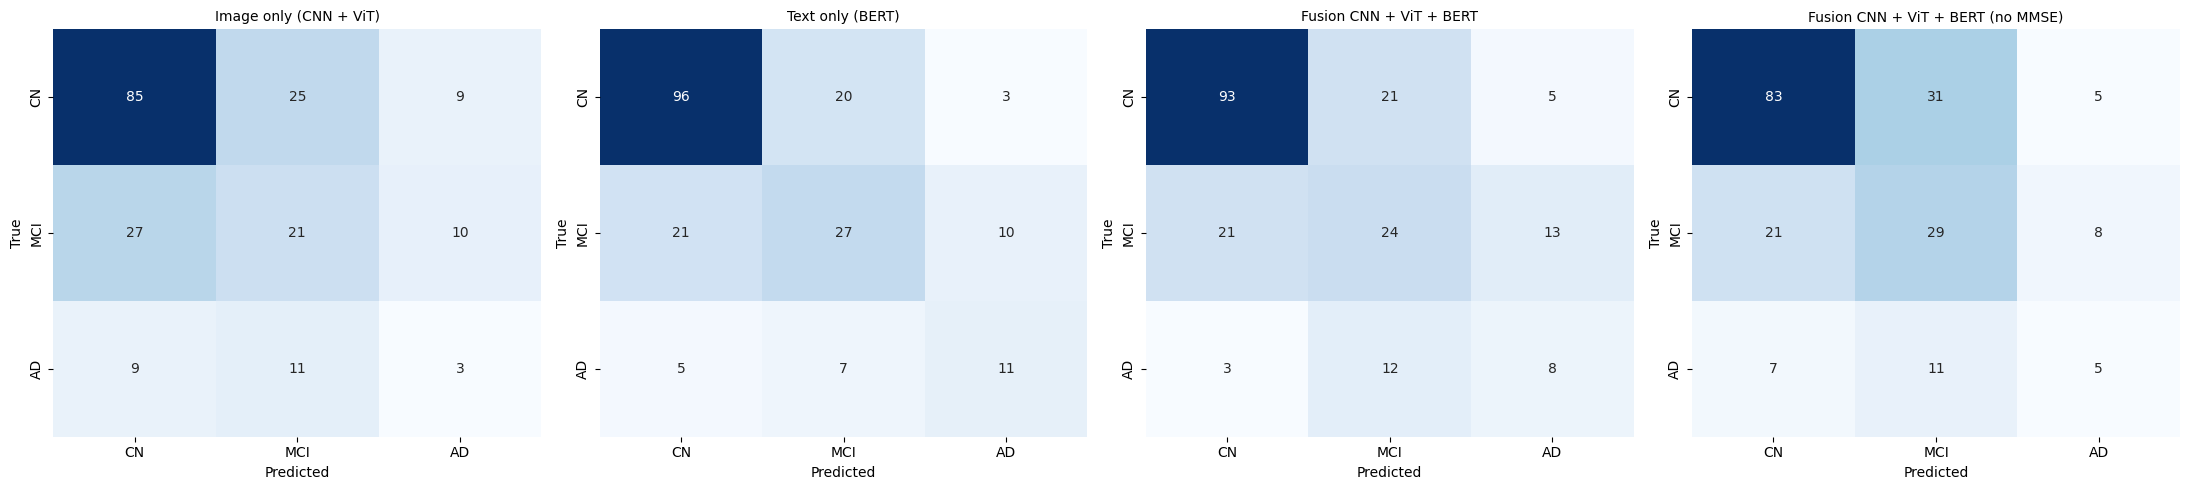

Per-class report — Fusion CNN + ViT + TF-IDF
              precision    recall  f1-score   support

          CN     0.7383    0.9244    0.8209       119
         MCI     0.5556    0.3448    0.4255        58
          AD     0.6000    0.3913    0.4737        23

    accuracy                         0.6950       200
   macro avg     0.6313    0.5535    0.5734       200
weighted avg     0.6694    0.6950    0.6663       200



In [12]:
show = ['Image only (CNN + ViT)', 'Text only (BERT)', 'Fusion CNN + ViT + BERT', 'Fusion CNN + ViT + BERT (no MMSE)']
fig, axes = plt.subplots(1, 4, figsize=(22, 5))
for ax, n in zip(axes, show):
    cm = confusion_matrix(y, oof[n].argmax(1), labels=range(C))
    sns.heatmap(cm, ax=ax, annot=True, fmt='d', cmap='Blues', cbar=False, xticklabels=LABELS, yticklabels=LABELS)
    ax.set_title(n, fontsize=10); ax.set_xlabel('Predicted'); ax.set_ylabel('True')
plt.tight_layout(); plt.savefig(f'{RES}/confusion_matrices.png', dpi=150); plt.show()

best_fusion = max([n for n in EXPERIMENTS if n.startswith('Fusion') and 'no MMSE' not in n], key=lambda n: results.loc[n, '_f1'])
print('Per-class report —', best_fusion)
print(classification_report(y, oof[best_fusion].argmax(1), target_names=LABELS, digits=4))

## 10) Does multimodal fusion improve performance?  (tested, not assumed)

In [13]:
from scipy.stats import binomtest

def compare(single_names, fusion_names):
    s = max(single_names, key=lambda n: results.loc[n, '_f1'])
    f = max(fusion_names, key=lambda n: results.loc[n, '_f1'])
    a, b = oof[s].argmax(1) == y, oof[f].argmax(1) == y
    n01, n10 = int((a & ~b).sum()), int((~a & b).sum())
    p = binomtest(n10, n01 + n10, 0.5).pvalue if n01 + n10 else 1.0      # exact McNemar test
    gain = results.loc[f, '_f1'] - results.loc[s, '_f1']
    verdict = ('Fusion SIGNIFICANTLY improves performance (p<0.05).' if gain > 0 and p < 0.05 else
               'Fusion is better on average, but NOT statistically significant.' if gain > 0 else
               'Fusion does NOT improve over the best single modality.')
    print(f'Best single : {s} (macro-F1 {results.loc[s, "_f1"]:.4f})\nBest fusion : {f} (macro-F1 {results.loc[f, "_f1"]:.4f})')
    print(f'Gain {gain:+.4f} macro-F1 | McNemar: fusion fixes {n10} patients, breaks {n01}; p = {p:.4g}\n-> {verdict}\n')
    return dict(best_single=s, fusion=f, gain_f1=float(gain), mcnemar_p=float(p), n_fixed=n10, n_broken=n01, verdict=verdict)

single = ['Image only (CNN + ViT)', 'Text only (TF-IDF)', 'Text only (BERT)']
print('=== Main setting (text includes MMSE) ===')
main = compare(single, ['Fusion CNN + ViT + TF-IDF', 'Fusion CNN + ViT + BERT'])
print('=== Ablation (MMSE removed from text) ===')
abl = compare(['Image only (CNN + ViT)', 'Text only (TF-IDF, no MMSE)', 'Text only (BERT, no MMSE)'],
              ['Fusion CNN + ViT + TF-IDF (no MMSE)', 'Fusion CNN + ViT + BERT (no MMSE)'])

json.dump({'dataset': 'OASIS-1 cross-sectional (Kaggle mirrors ninadaithal/imagesoasis + jboysen/mri-and-alzheimers)',
           'n_patients': int(len(y)), 'class_counts': {n: int((y == i).sum()) for i, n in enumerate(LABELS)},
           'n_folds': N_FOLDS, 'seeds': SEEDS, 'n_slices': N_SLICES, 'pca_dim': PCA_DIM,
           'main': main, 'ablation_no_mmse': abl}, open(f'{RES}/summary.json', 'w'), indent=2)
print('Saved to', RES)

=== Main setting (text includes MMSE) ===
Best single : Text only (TF-IDF) (macro-F1 0.5577)
Best fusion : Fusion CNN + ViT + TF-IDF (macro-F1 0.5530)
Gain -0.0047 macro-F1 | McNemar: fusion fixes 11 patients, breaks 13; p = 0.8388
-> Fusion does NOT improve over the best single modality.

=== Ablation (MMSE removed from text) ===
Best single : Text only (BERT, no MMSE) (macro-F1 0.4572)
Best fusion : Fusion CNN + ViT + BERT (no MMSE) (macro-F1 0.4185)
Gain -0.0387 macro-F1 | McNemar: fusion fixes 20 patients, breaks 24; p = 0.6516
-> Fusion does NOT improve over the best single modality.

Saved to /content/drive/MyDrive/MM_Project1/results
